# PrivacyShield — Exploratory Data Analysis and Preprocessing

**Course:** CS 6220 — Data Mining Techniques

## Project Overview

PrivacyShield aims to detect personally identifiable information (PII) in text using Natural Language Processing (NLP) and machine learning techniques.

The project uses NVIDIA's Nemotron-PII dataset, which contains annotated text records from multiple industries and document formats.

### Objectives

1. Understand the structure and characteristics of the training and test datasets.
2. Examine data quality, entity annotations, and PII label distributions.
3. Investigate patterns across industries, document formats, locales, and text lengths.
4. Identify potential preprocessing requirements and data leakage risks.
5. Prepare the data for supervised token classification models.

### Dataset

**Source:** https://huggingface.co/datasets/nvidia/Nemotron-PII

**Files:**
- `train.parquet`
- `test.parquet`

The original test dataset will be reserved for final model evaluation.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

# Notebook is inside code/, datasets are inside data/
DATA_DIR = Path("../data")

train_df = pd.read_parquet(DATA_DIR / "train.parquet")
test_df = pd.read_parquet(DATA_DIR / "test.parquet")

print("Training data:", train_df.shape)
print("Test data:", test_df.shape)
print("Columns:", train_df.columns.tolist())

Training data: (100000, 9)
Test data: (100000, 9)
Columns: ['uid', 'domain', 'document_type', 'document_description', 'document_format', 'locale', 'text', 'spans', 'text_tagged']


### 1.1 Dataset Structure and Data Types

We examine the dimensions and data types of the training and test datasets to understand how the data is organized.

We also verify that both datasets contain the same columns before proceeding with exploratory data analysis and preprocessing.


In [2]:
print("Training dataset data types:")
display(train_df.dtypes.to_frame("Data Type"))

print("\nTest dataset data types:")
display(test_df.dtypes.to_frame("Data Type"))

print("\nDo both datasets have the same columns?")
print(train_df.columns.equals(test_df.columns))

Training dataset data types:


,Data Type
uid,str
domain,str
document_type,str
document_description,str
document_format,str
locale,str
text,str
spans,str
text_tagged,str



Test dataset data types:


,Data Type
uid,str
domain,str
document_type,str
document_description,str
document_format,str
locale,str
text,str
spans,str
text_tagged,str



Do both datasets have the same columns?
True


### Observations

- Both the training and test datasets contain 9 columns with identical names and data types.
- All columns are stored as strings.
- The `spans` column contains PII annotations represented as strings, which will need to be converted into structured data during preprocessing.
- The matching dataset structures allow us to apply consistent preprocessing to both datasets.

### Significance

The dataset structure is consistent across the training and test sets.

For our NLP models, the `text` column will serve as the input, while the annotations in `spans` will provide the target labels.

We will keep the original test set separate to avoid data leakage during model development.



## 2. Data Quality Analysis

### 2.1 Missing Values

We check for missing values in the training and test datasets to identify any incomplete records that may require handling during preprocessing.


In [3]:
print("Missing values in training data:")
display(train_df.isnull().sum().to_frame("Missing Count"))

print("\nMissing values in test data:")
display(test_df.isnull().sum().to_frame("Missing Count"))

Missing values in training data:


,Missing Count
uid,0
domain,0
document_type,0
document_description,0
document_format,0
locale,0
text,0
spans,0
text_tagged,0



Missing values in test data:


,Missing Count
uid,0
domain,0
document_type,0
document_description,0
document_format,0
locale,0
text,0
spans,0
text_tagged,0


### Observations

- Both training and test datasets contain zero missing values across all nine columns.
- No null-value imputation is required based on the initial missing-value analysis.
- Further checks are needed to identify empty strings or invalid annotations that may not appear as missing values.

### Significance

The absence of missing values simplifies the initial preprocessing process.

However, additional data quality checks are necessary before model training, particularly for duplicate records and the consistency of PII annotations.


### 2.2 Duplicate Analysis

We examine duplicate records, repeated UIDs, and duplicate text values in both datasets.

The purpose is to identify repeated observations and understand whether they represent duplicate documents or intentionally related records.

Repeated UIDs will be investigated before deciding whether any records should be removed.


In [4]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")
    print("Fully duplicate rows:", data.duplicated().sum())
    print("Duplicate UIDs:", data["uid"].duplicated().sum())
    print("Duplicate texts:", data["text"].duplicated().sum())
    print("Unique UIDs:", data["uid"].nunique())


Training Dataset
Fully duplicate rows: 0
Duplicate UIDs: 50000
Duplicate texts: 1
Unique UIDs: 50000

Test Dataset
Fully duplicate rows: 0
Duplicate UIDs: 50000
Duplicate texts: 0
Unique UIDs: 50000



### Observations

- Neither the training nor the test dataset contains fully duplicated rows.
- Both datasets contain 100,000 records and 50,000 unique UIDs.
- Each dataset has 50,000 repeated UID occurrences.
- The training dataset contains one duplicate text, while the test dataset contains none.
- Earlier analysis of the training data showed that records sharing a UID have matching document metadata but different locales.

### Significance

The repeated UIDs may represent locale-specific variations of the same document scenario rather than accidental duplicate records.

Therefore, we will retain these records during EDA and investigate their relationships before preprocessing.

When creating a validation split, related records should be kept together to reduce the risk of data leakage.


### 2.3 Train/Test Overlap

We check whether the training and test datasets share record identifiers or identical text values.

Overlapping records could affect the independence of the held-out test set and potentially inflate model performance.

This check identifies exact overlaps; additional analysis would be required to detect near-duplicate text or similar document templates.


In [5]:
# Check overlaps between training and test datasets

shared_uids = set(train_df["uid"]) & set(test_df["uid"])
shared_texts = set(train_df["text"]) & set(test_df["text"])

print("Shared UIDs:", len(shared_uids))
print("Shared texts:", len(shared_texts))

Shared UIDs: 0
Shared texts: 0


### Observations

- There are no shared UIDs between the training and test datasets.
- There are no identical text records across the two datasets.
- The results indicate that the original train and test splits are distinct based on exact identifier and text matching.

### Significance

The absence of exact overlap reduces the risk of data leakage between training and testing.

However, because the dataset contains synthetically generated documents, similar templates or document scenarios may still appear across the splits.

We will preserve the original test set for final model evaluation and investigate potential near-duplicate records during further data quality analysis.



## 3. Individual Column Analysis

Each column is analyzed independently to understand its meaning, distribution, data quality, and relevance to the PrivacyShield project.

For each column, we will document:

1. **Description:** What the column represents.
2. **Objective:** What we want to investigate.
3. **Analysis:** Python code and relevant visualizations.
4. **Observations:** Findings based on the actual data.
5. **Significance:** How the findings affect preprocessing, modeling, or evaluation.


## 3. Individual Column Analysis

### 3.1 UID — Record Identifier

The `uid` column contains identifiers associated with dataset records.

#### Objective

- Determine how many unique UIDs exist in each dataset.
- Examine how frequently each UID appears.
- Investigate whether repeated UIDs are associated with related document scenarios.
- Determine how the UID column should be handled during data splitting.


In [6]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    print("Total records:", len(data))
    print("Unique UIDs:", data["uid"].nunique())

    print("\nUID frequency distribution:")
    display(
        data["uid"]
        .value_counts()
        .value_counts()
        .sort_index()
        .to_frame("Number of UIDs")
    )


Training Dataset
Total records: 100000
Unique UIDs: 50000

UID frequency distribution:


,Number of UIDs
count,
2,50000



Test Dataset
Total records: 100000
Unique UIDs: 50000

UID frequency distribution:


,Number of UIDs
count,
2,50000


#### Observations

- Both training and test datasets contain 100,000 records and 50,000 unique UIDs.
- Every UID appears exactly twice in each dataset.
- This indicates that UIDs are not unique row identifiers.
- Further investigation is needed to determine how records sharing the same UID are related.

#### Significance

Understanding the relationship between records sharing a UID is important for preprocessing and data splitting.

If the records represent variations of the same document scenario, they should remain in the same training or validation group to reduce the risk of data leakage.


### 3.1.1 Relationship Between Records Sharing a UID

Since each UID appears exactly twice, we investigate whether these records share document characteristics or represent different variations of the same document.

We compare metadata fields across records grouped by UID to understand the purpose of repeated identifiers.


In [7]:
columns_to_check = [
    "domain",
    "document_type",
    "document_description",
    "document_format",
    "locale",
    "text"
]

for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    for col in columns_to_check:
        same_count = (
            data.groupby("uid")[col].nunique() == 1
        ).sum()

        print(
            f"{col}: {same_count:,} out of "
            f"{data['uid'].nunique():,} UIDs have identical values"
        )


Training Dataset
domain: 50,000 out of 50,000 UIDs have identical values
document_type: 50,000 out of 50,000 UIDs have identical values
document_description: 50,000 out of 50,000 UIDs have identical values
document_format: 50,000 out of 50,000 UIDs have identical values
locale: 0 out of 50,000 UIDs have identical values
text: 1 out of 50,000 UIDs have identical values

Test Dataset
domain: 50,000 out of 50,000 UIDs have identical values
document_type: 50,000 out of 50,000 UIDs have identical values
document_description: 50,000 out of 50,000 UIDs have identical values
document_format: 50,000 out of 50,000 UIDs have identical values
locale: 0 out of 50,000 UIDs have identical values
text: 0 out of 50,000 UIDs have identical values


#### Final Observations — UID

- Both training and test datasets contain 50,000 unique UIDs, with each UID appearing exactly twice.
- Records sharing a UID have identical `domain`, `document_type`, `document_description`, and `document_format` values.
- The `locale` values differ for every UID pair in both datasets.
- In the training dataset, 49,999 UID pairs contain different text, while one pair contains identical text.
- In the test dataset, all 50,000 UID pairs contain different text.

#### Interpretation

The results suggest that each UID represents a document scenario with two locale-specific variations.

These repeated identifiers do not represent fully duplicated records and should not be removed solely because their UIDs repeat.

#### Preprocessing Implications

- Retain both records associated with each UID.
- Treat UID as a grouping identifier rather than an input feature for the PII detection model.
- When creating a training/validation split, ensure that both records sharing a UID remain in the same split.
- Use a group-aware splitting strategy, such as `GroupShuffleSplit`, to reduce potential leakage between related document scenarios.


### 3.2 Domain — Industry or Subject Area

The `domain` column represents the industry or subject area associated with each document.

#### Objectives

- Identify the number of unique domains.
- Examine the distribution of documents across domains.
- Compare domain distributions between training and test datasets.
- Identify potential class imbalance across industries.

#### Significance

Domain analysis helps us understand the diversity of the dataset and whether certain industries are overrepresented.

It will also support subgroup evaluation to determine whether our PII detection models perform consistently across different industries.


In [8]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")
    print("Number of unique domains:", data["domain"].nunique())

    domain_counts = data["domain"].value_counts()

    display(
        domain_counts.to_frame("Document Count")
    )


Training Dataset
Number of unique domains: 30


,Document Count
domain,
Finance,3990
Technology,3988
Cybersecurity,3890
Identity Management,3750
Identity Verification Services,3722
Telecommunications,3662
Healthcare,3630
Government,3566
Civil Rights,3546



Test Dataset
Number of unique domains: 29


,Document Count
domain,
Banking,3840
User Account and Transaction Services,3794
Information Technology,3786
Brokerage,3762
Access Control Systems,3728
Credit,3714
Disability,3634
Life,3632
Marketing,3622


#### Initial Observations

- The training dataset contains 30 unique domains, while the test dataset contains 29.
- Finance (3,990 records) and Technology (3,988 records) are the most frequent training domains.
- Banking (3,840 records) and User Account and Transaction Services (3,794 records) are the most frequent test domains.
- Domain frequencies vary, but no single domain dominates either dataset.
- The domain categories differ substantially between the training and test sets.

#### Significance

The differences in domain categories suggest that the held-out test dataset may be useful for evaluating cross-domain generalization.

For PrivacyShield, this is important because PII detection models should ideally recognize sensitive information across different industries and document contexts.

Further analysis is required to identify exactly which domains are shared and which are exclusive to each dataset.


### 3.2.1 Domain Overlap Between Training and Test Sets

We compare the unique domain categories in both datasets to determine whether the original test set contains industries not explicitly represented in the training set.

This helps assess potential distribution differences and informs our model evaluation strategy.


In [9]:
train_domains = set(train_df["domain"].unique())
test_domains = set(test_df["domain"].unique())

shared_domains = train_domains & test_domains
train_only = train_domains - test_domains
test_only = test_domains - train_domains

print("Shared domains:", sorted(shared_domains))
print("Number of shared domains:", len(shared_domains))

print("\nDomains only in training:", sorted(train_only))
print("Number:", len(train_only))

print("\nDomains only in testing:", sorted(test_only))
print("Number:", len(test_only))

Shared domains: ['Insurance']
Number of shared domains: 1

Domains only in training: ['Agriculture', 'Automotive', 'Biotechnology', 'Chemicals', 'Civil Rights', 'Construction', 'Consumer Goods', 'Cybersecurity', 'Ecommerce', 'Education', 'Energy', 'Entertainment', 'Finance', 'Government', 'Healthcare', 'Hospitality', 'Identity Management', 'Identity Verification Services', 'Legal', 'Logistics', 'Manufacturing', 'Media', 'Non-Profit', 'Pharmaceuticals', 'Real Estate', 'Retail', 'Technology', 'Telecommunications', 'Transportation']
Number: 29

Domains only in testing: ['Access Control Systems', 'Advertising', 'Automobile', 'Banking', 'Brokerage', 'Casualty', 'Consulting', 'Credit', 'Disability', 'Elections', 'Environmental', 'Fitness', 'Health', 'Healthcare Providers', 'Human Resources', 'Information Technology', 'Investment', 'Life', 'Marketing', 'Mortgage', 'Product', 'Property', 'Public Safety', 'Services', 'Social Science', 'Sports', 'Travel', 'User Account and Transaction Services']

#### Observations — Domain Overlap

- The training dataset contains 30 unique domains, while the test dataset contains 29.
- Only one domain, `Insurance`, is shared between the two datasets.
- There are 29 domains exclusive to training and 28 domains exclusive to testing.
- Across both datasets, there are 58 distinct domain categories.

#### Interpretation

The training and test datasets have substantially different domain-category distributions.

This indicates that the original test set can be used to investigate how well PII detection models generalize to domain categories not represented during training.

However, some categories may be semantically related despite having different names, so the results should not be interpreted as complete separation of document content.

#### Implications for Modeling

- Use the original training dataset for model development.
- Create a separate group-aware validation split from the training data.
- Preserve the original test dataset for final evaluation.
- During final evaluation, compare model performance on the shared domain (`Insurance`) and unseen domain categories.
- Investigate performance differences across individual domains where sufficient examples are available.


### 3.2.2 Domain Distribution Visualization

We visualize the frequency of documents across domains in both datasets to compare their distributions and identify potential imbalances.

The domains are displayed separately for training and test datasets because most categories are not shared.


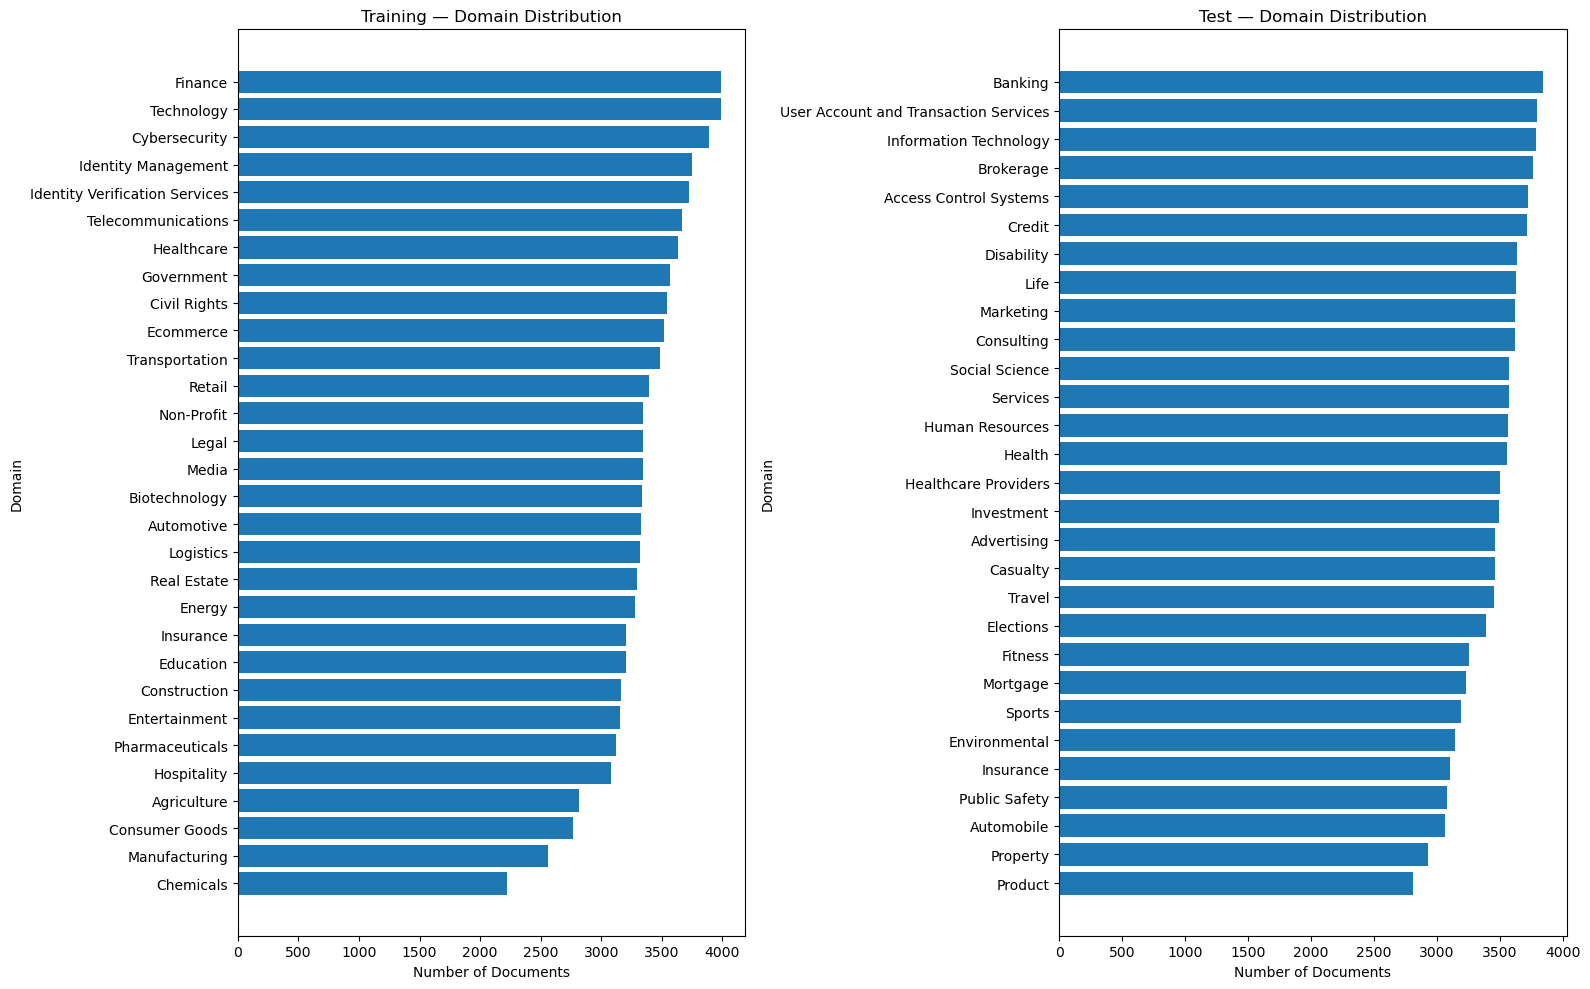

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

for ax, (name, data) in zip(
    axes,
    [("Training", train_df), ("Test", test_df)]
):
    counts = data["domain"].value_counts().sort_values()

    ax.barh(counts.index, counts.values)
    ax.set_title(f"{name} — Domain Distribution")
    ax.set_xlabel("Number of Documents")
    ax.set_ylabel("Domain")

plt.tight_layout()
plt.show()

### 3.3 Document Type — Document Category

The `document_type` column identifies the type of document represented by each record, such as customer support tickets, reports, forms, or user guides.

#### Objectives

- Determine the number of unique document types in each dataset.
- Identify the most and least frequent document types.
- Understand the distribution of document categories.
- Investigate whether certain document types are underrepresented.

#### Significance

Different document types may contain different patterns of personally identifiable information (PII).

Understanding their distribution will help us evaluate whether our PII detection models perform consistently across document categories.


In [11]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    counts = data["document_type"].value_counts()

    print("Unique document types:", data["document_type"].nunique())

    print("\nTop 10 most frequent document types:")
    display(counts.head(10).to_frame("Document Count"))

    print("\nBottom 10 least frequent document types:")
    display(counts.tail(10).to_frame("Document Count"))


Training Dataset
Unique document types: 1451

Top 10 most frequent document types:


,Document Count
document_type,
Customer Support Ticket,394
Environmental Impact Assessment,388
User Guide,360
Safety Data Sheet,316
Job Application Form,286
Room Service Menu,286
email,268
Service Level Agreement,262
Annual Report,260



Bottom 10 least frequent document types:


,Document Count
document_type,
Product Comparison Chart,10
Chemical Storage Checklist,10
Weather Forecast,8
Design Specifications,8
Technical Data Sheet,6
Class Schedule,6
Chemical Compatibility Chart,6
Course Prerequisites,6
Product description,6



Test Dataset
Unique document types: 1466

Top 10 most frequent document types:


,Document Count
document_type,
Investment Strategy,434
User Guide,310
Risk Management Plan,286
Incident Report,262
Voter Registration Form,258
Claim Form,242
Service Level Agreement,242
Credit Report,240
Customer Feedback Form,234



Bottom 10 least frequent document types:


,Document Count
document_type,
Salary Structure Chart,12
Data Sheet,12
Event Attendance Report,10
Product Safety Data Sheet,10
Product Catalog,8
Event Ticket Sales Report,6
Equipment Inventory,4
Product Comparison Chart,4
Emergency Medical Supplies Inventory,4



#### Observations — Document Type

- The training dataset contains 1,451 unique document types, while the test dataset contains 1,466.
- Customer Support Ticket (394 records) is the most frequent document type in training.
- Investment Strategy (434 records) is the most frequent document type in testing.
- Some document types occur only a few times, indicating an uneven, long-tailed distribution.
- There are potential naming inconsistencies, including differences in capitalization.

#### Significance

The dataset includes a wide variety of document categories, which may expose PII detection models to different text structures and contexts.

The uneven distribution suggests that performance across document types should be examined carefully, particularly for less frequent categories.

Before preprocessing, we should investigate naming inconsistencies and overlap between training and test document types.

We will not remove rare document types solely because they have low frequencies.



### 3.3.1 Document Type Overlap

We compare document types between training and test datasets to identify shared and exclusive categories.

This analysis helps determine whether the model will encounter familiar document categories during final testing, even when the industry domains differ.


In [12]:
train_types = set(train_df["document_type"].unique())
test_types = set(test_df["document_type"].unique())

shared_types = train_types & test_types
train_only_types = train_types - test_types
test_only_types = test_types - train_types

print("Shared document types:", len(shared_types))
print("Document types only in training:", len(train_only_types))
print("Document types only in testing:", len(test_only_types))

print("\nExamples of shared document types:")
print(sorted(shared_types)[:20])

Shared document types: 281
Document types only in training: 1170
Document types only in testing: 1185

Examples of shared document types:
['API Documentation', 'ATM card PIN mailer', 'Accident Report', 'Account Registration Form', 'Ad Copy', 'Age Verification', 'Allergy Information', 'Annual Report', 'Application Setup Guide', 'Appraisal Report', 'Audio Ad Script', 'Audit Report', 'Authentication Token', 'Author Contract', 'Authorization Token', 'Background Check Authorization Form', 'Bank Account Opening Form', 'Bank Statement', 'Beneficiary Designation Form', 'Beneficiary Form']



#### Observations — Document Type Overlap

- There are 281 document types shared between the training and test datasets.
- The training dataset contains 1,170 document types that do not appear in testing.
- The test dataset contains 1,185 document types that do not appear in training.
- Across both datasets, there are 2,636 unique document types.
- Examples of shared categories include `API Documentation`, `Annual Report`, and `Bank Statement`.

#### Significance

Although the training and test datasets have substantially different domain categories, some document types are represented in both.

This provides an opportunity to investigate model generalization across familiar and unfamiliar document categories.

During final evaluation, we can compare PII detection performance between document types seen during training and those appearing only in the test set.

Document types with very few examples will need careful interpretation when reporting subgroup performance.



### 3.3.2 Document Type Distribution Visualization

We visualize the 15 most frequent document types in each dataset.

Because the datasets contain a large number of distinct document types, displaying every category would make the chart difficult to interpret.

This visualization highlights the most common document categories and allows us to compare their frequencies.


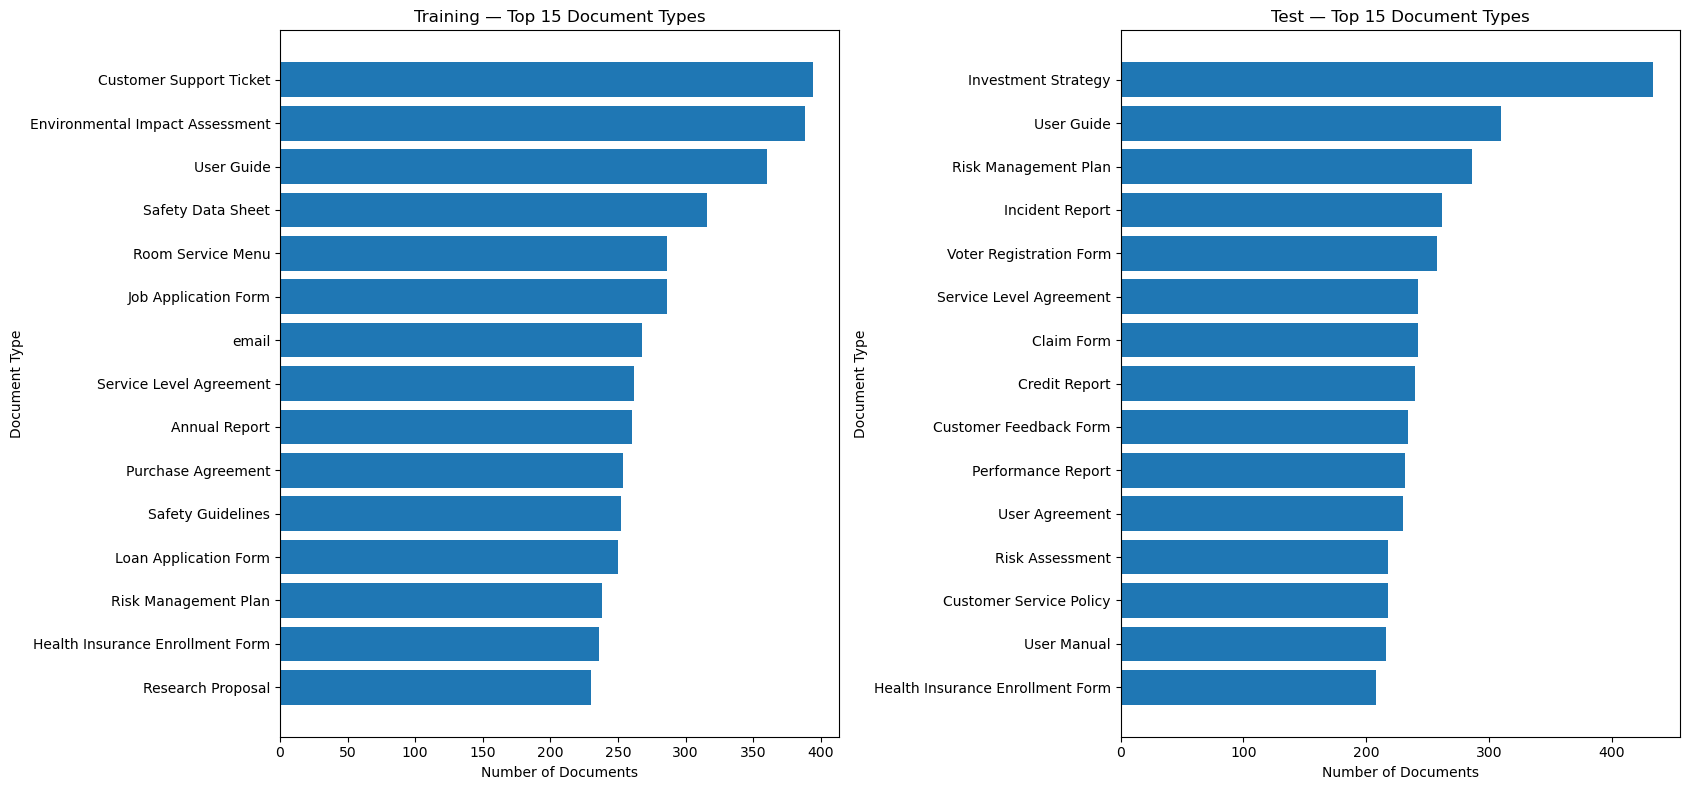

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8))

for ax, (name, data) in zip(
    axes,
    [("Training", train_df), ("Test", test_df)]
):
    counts = data["document_type"].value_counts().head(15).sort_values()

    ax.barh(counts.index, counts.values)
    ax.set_title(f"{name} — Top 15 Document Types")
    ax.set_xlabel("Number of Documents")
    ax.set_ylabel("Document Type")

plt.tight_layout()
plt.show()


### 3.4 Document Description

The `document_description` column provides information about the purpose, content, or scenario associated with each document.

#### Objectives

- Determine the number of unique document descriptions.
- Identify repeated descriptions.
- Examine the frequency of repeated document scenarios.
- Understand whether descriptions can help identify related records.

#### Significance

Repeated descriptions may indicate that multiple records were generated from similar underlying document scenarios.

Understanding these patterns can help us identify potential similarities between records and reduce data leakage during model development.


In [14]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    description_counts = data["document_description"].value_counts()

    print("Total records:", len(data))
    print("Unique descriptions:", data["document_description"].nunique())
    print("Repeated description values:",
          (description_counts > 1).sum())
    print("Maximum occurrences of a description:",
          description_counts.max())

    print("\nFrequency distribution:")
    display(
        description_counts.value_counts()
        .sort_index()
        .to_frame("Number of Descriptions")
    )


Training Dataset
Total records: 100000
Unique descriptions: 49981
Repeated description values: 49981
Maximum occurrences of a description: 4

Frequency distribution:


,Number of Descriptions
count,
2,49962
4,19



Test Dataset
Total records: 100000
Unique descriptions: 49987
Repeated description values: 49987
Maximum occurrences of a description: 6

Frequency distribution:


,Number of Descriptions
count,
2,49975
4,11
6,1



#### Observations — Document Description

- The training dataset contains 49,981 unique document descriptions, while the test dataset contains 49,987.
- Most descriptions appear exactly twice, consistent with the two records associated with each UID.
- In training, 19 descriptions appear four times.
- In testing, 11 descriptions appear four times and one description appears six times.
- Some document descriptions may therefore be reused across multiple UIDs.

#### Significance

Repeated document descriptions may indicate related document scenarios.

Although grouping records by UID helps keep locale-specific variations together, different UIDs could potentially share similar document descriptions.

We should investigate these relationships before finalizing our training and validation splitting strategy.



### 3.4.1 Relationship Between Document Description and UID

We investigate whether identical document descriptions are associated with multiple UIDs.

This helps determine whether UID-based grouping alone is sufficient to separate related document scenarios during model development.


In [15]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    uids_per_description = (
        data.groupby("document_description")["uid"]
        .nunique()
    )

    print("Distribution of unique UIDs per description:")
    display(
        uids_per_description.value_counts()
        .sort_index()
        .to_frame("Number of Descriptions")
    )

    print(
        "Descriptions associated with multiple UIDs:",
        (uids_per_description > 1).sum()
    )


Training Dataset
Distribution of unique UIDs per description:


,Number of Descriptions
uid,
1,49962
2,19


Descriptions associated with multiple UIDs: 19

Test Dataset
Distribution of unique UIDs per description:


,Number of Descriptions
uid,
1,49975
2,11
3,1


Descriptions associated with multiple UIDs: 12



#### Observations — Relationship Between Document Description and UID

- In the training dataset, 49,962 descriptions are associated with one UID, while 19 descriptions are associated with two UIDs.
- In the test dataset, 49,975 descriptions are associated with one UID, 11 with two UIDs, and one with three UIDs.
- This confirms that a small number of descriptions are reused across different UIDs.

#### Significance

Most repeated descriptions correspond to records sharing the same UID. However, some descriptions are associated with multiple UIDs.

When creating the training and validation splits, grouping by UID will keep locale-specific versions together but may not prevent identical document descriptions from appearing in both splits.

We should investigate these shared descriptions and consider additional grouping or overlap checks to reduce potential data leakage.

No records will be removed at this stage.


### 3.5 Document Format

The `document_format` column describes how information is organized within a document.

#### Objectives

- Identify the unique document formats.
- Examine their distribution in training and test datasets.
- Determine whether certain formats are more common than others.

#### Significance

Structured and unstructured documents may present different challenges for PII detection.

For example, structured documents may contain identifiable fields such as `Email:` or `Date of Birth:`, while unstructured documents may mention the same information within natural-language sentences.

Analyzing document formats will help us evaluate model performance across different text structures.


In [16]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    format_counts = data["document_format"].value_counts()

    format_summary = pd.DataFrame({
        "Count": format_counts,
        "Percentage (%)": (
            format_counts / len(data) * 100
        ).round(2)
    })

    display(format_summary)


Training Dataset


,Count,Percentage (%)
document_format,,
unstructured,51364,51.36
structured,48636,48.64



Test Dataset


,Count,Percentage (%)
document_format,,
unstructured,50578,50.58
structured,49422,49.42



#### Observations — Document Format

- Both training and test datasets contain two document formats: `structured` and `unstructured`.
- In training, 51.36% of documents are unstructured and 48.64% are structured.
- In testing, 50.58% of documents are unstructured and 49.42% are structured.
- The distribution is nearly balanced in both datasets, with a slight majority of unstructured documents.

#### Significance

The balanced representation of structured and unstructured documents allows us to evaluate PII detection performance across both formats.

During model evaluation, we can compare precision, recall, and F1-score separately for structured and unstructured documents to investigate whether document organization affects detection performance.

No format-specific preprocessing is required based on the distribution alone.



### 3.5.1 Document Format Distribution Visualization

We compare the percentage of structured and unstructured documents in the training and test datasets.

Percentages are used to make the distributions easy to compare.


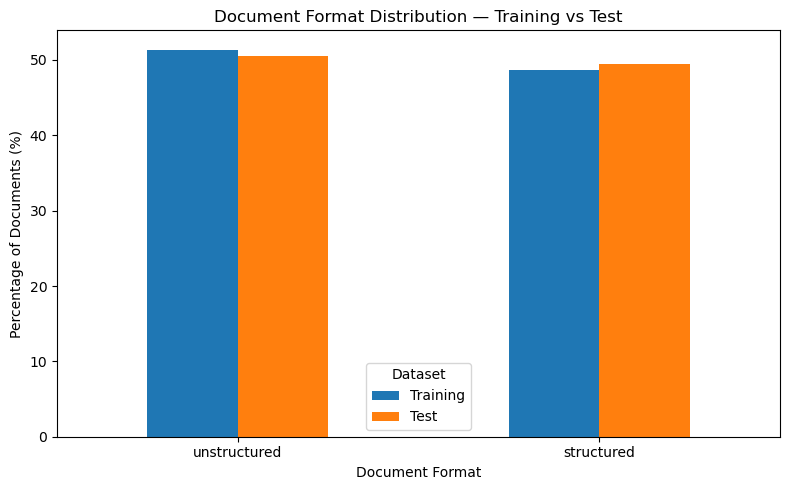

In [17]:
format_comparison = pd.DataFrame({
    "Training": train_df["document_format"].value_counts(normalize=True) * 100,
    "Test": test_df["document_format"].value_counts(normalize=True) * 100
})

ax = format_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Document Format Distribution — Training vs Test")
ax.set_xlabel("Document Format")
ax.set_ylabel("Percentage of Documents (%)")
ax.legend(title="Dataset")

plt.tight_layout()
plt.show()


### 3.6 Locale — Regional Context

The `locale` column indicates the regional context associated with each document.

#### Objectives

- Identify the unique locale categories.
- Examine the distribution of records across locales.
- Compare locale distributions between training and test datasets.
- Understand how locale variations may affect PII detection.

#### Significance

PII such as phone numbers, addresses, postal codes, and identification numbers may follow different formats across regions.

Analyzing locale distributions will help us understand the dataset's regional diversity and support evaluation of model performance across different locale categories.


In [18]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    locale_counts = data["locale"].value_counts()

    locale_summary = pd.DataFrame({
        "Count": locale_counts,
        "Percentage (%)": (
            locale_counts / len(data) * 100
        ).round(2)
    })

    display(locale_summary)


Training Dataset


,Count,Percentage (%)
locale,,
us,50000,50.0
intl,50000,50.0



Test Dataset


,Count,Percentage (%)
locale,,
us,50000,50.0
intl,50000,50.0



#### Observations — Locale

- Both training and test datasets contain two locale categories: `us` and `intl`.
- Each dataset contains 50,000 US records and 50,000 international records.
- The locale distribution is exactly balanced at 50% each.

#### Significance

The balanced locale distribution allows us to evaluate model performance across US and international document contexts.

This is particularly relevant for PII categories such as addresses, phone numbers, postal codes, and identification numbers, which may have different regional formatting conventions.

However, the `intl` category does not necessarily indicate multilingual text.

We will also investigate whether the two records associated with each UID represent one US and one international version.



### 3.6.1 Locale Distribution Within UID Groups

We investigate the locale combinations associated with each UID.

Since every UID appears twice, we want to verify whether each pair contains one `us` record and one `intl` record.


In [20]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    locale_pairs = (
        data.groupby("uid")["locale"]
        .agg(lambda x: tuple(sorted(x)))
    )

    print("Locale combinations per UID:")
    display(
        locale_pairs.value_counts()
        .to_frame("Number of UIDs")
    )


Training Dataset
Locale combinations per UID:


,Number of UIDs
locale,
"(intl, us)",50000



Test Dataset
Locale combinations per UID:


,Number of UIDs
locale,
"(intl, us)",50000



#### Final Observations — Locale

- Both training and test datasets contain an equal number of `us` and `intl` records.
- Every UID appears exactly twice, with one `us` record and one `intl` record.
- The two records associated with each UID share the same document metadata but differ in their regional context.
- This confirms that each UID represents a pair of locale-specific document records.

#### Significance

The dataset provides balanced representation of US and international document contexts.

This is valuable for evaluating whether PII detection models perform consistently across different regional formatting conventions.

During preprocessing, both records associated with the same UID should remain in the same training or validation split to prevent related document scenarios from being separated.

We will retain both locale variations rather than removing one as a duplicate.



### 3.7 Text — Document Content

The `text` column contains the actual document content used as input for PII detection.

#### Objectives

- Check whether any records contain empty or whitespace-only text.
- Analyze document lengths in characters and words.
- Examine the distribution of document lengths.
- Identify unusually short or long documents.
- Understand potential challenges for NLP tokenization and model training.

#### Significance

Document length and structure can influence PII detection performance.

Long documents may exceed the maximum input length supported by transformer models, requiring chunking or other strategies.

Short documents may provide limited context for identifying sensitive information.

Understanding these characteristics will help us design appropriate preprocessing steps.


In [21]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    empty_text = data["text"].eq("").sum()
    whitespace_only = data["text"].str.strip().eq("").sum()

    print("Empty text records:", empty_text)
    print("Whitespace-only or empty text records:", whitespace_only)


Training Dataset
Empty text records: 0
Whitespace-only or empty text records: 0

Test Dataset
Empty text records: 0
Whitespace-only or empty text records: 0



#### Observations — Empty Text Analysis

- Neither the training nor the test dataset contains empty text records.
- No records contain only whitespace.
- All 200,000 records contain non-empty text.

#### Significance

No records need to be removed due to empty or whitespace-only document content.

However, we still need to investigate document lengths and annotation quality before determining the preprocessing requirements.



### 3.7.1 Document Length Analysis

We analyze document lengths using character counts and approximate word counts.

#### Objectives

- Calculate the mean, median, minimum, and maximum document lengths.
- Examine the variation in document lengths.
- Compare document lengths between training and test datasets.
- Identify whether long documents may require special handling during model preprocessing.

Character counts include spaces and punctuation, while word counts are calculated using whitespace splitting.


In [22]:
# Calculate document lengths for both datasets

for name, data in [("Training", train_df), ("Test", test_df)]:

    print(f"\n{name} Dataset")

    data["char_count"] = data["text"].str.len()
    data["word_count"] = data["text"].str.split().str.len()

    print("\nCharacter Count Statistics:")
    display(data["char_count"].describe().to_frame("Character Count"))

    print("\nWord Count Statistics:")
    display(data["word_count"].describe().to_frame("Word Count"))


Training Dataset

Character Count Statistics:


,Character Count
count,100000.000000
mean,1003.448720
std,732.674755
min,32.000000
25%,505.000000
50%,774.000000
75%,1273.000000
max,13260.000000



Word Count Statistics:


,Word Count
count,100000.000000
mean,134.525810
std,99.335153
min,2.000000
25%,67.000000
50%,103.000000
75%,171.000000
max,1303.000000



Test Dataset

Character Count Statistics:


,Character Count
count,100000.000000
mean,958.538440
std,699.022198
min,45.000000
25%,483.000000
50%,745.000000
75%,1203.000000
max,14608.000000



Word Count Statistics:


,Word Count
count,100000.000000
mean,129.478410
std,94.929106
min,4.000000
25%,64.000000
50%,100.000000
75%,163.000000
max,1148.000000



#### Observations — Document Length

- The training dataset has an average document length of 1,003 characters and 135 words.
- The test dataset has an average document length of 959 characters and 129 words.
- Median word counts are 103 for training and 100 for testing.
- In both datasets, the mean exceeds the median, suggesting right-skewed document length distributions.
- Document lengths vary considerably, ranging from 2 to 1,303 words in training and 4 to 1,148 words in testing.
- The longest test document contains 14,608 characters, exceeding the training maximum of 13,260 characters.

#### Significance

The training and test datasets have broadly similar document length characteristics, although training documents are slightly longer on average.

The variation in document lengths is important for NLP model development.

Some documents may exceed the input length supported by transformer models such as DistilBERT. We will examine tokenizer-based sequence lengths during preprocessing to determine whether chunking is necessary.

We will avoid arbitrarily truncating documents because this could remove annotated PII entities and negatively affect detection performance.



### 3.7.2 Document Length Distribution

We visualize the approximate word-count distribution in the training and test datasets.

The purpose is to examine document length variability, identify skewness, and compare the overall distributions.

Word counts are calculated using whitespace splitting and do not represent transformer tokenizer lengths.


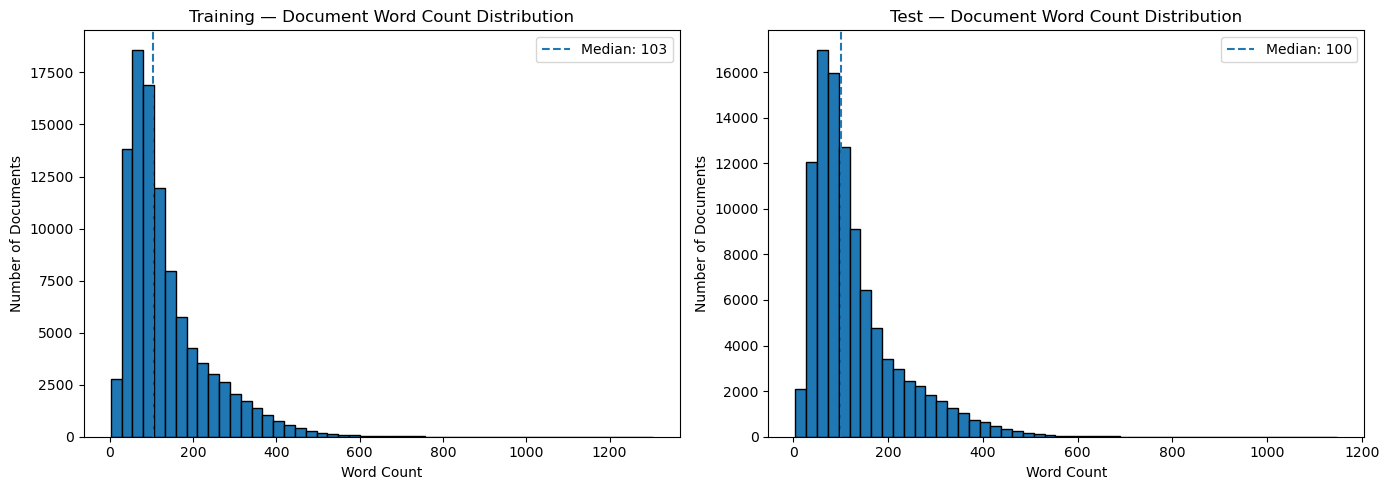

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, data) in zip(
    axes,
    [("Training", train_df), ("Test", test_df)]
):
    ax.hist(data["word_count"], bins=50, edgecolor="black")
    ax.axvline(
        data["word_count"].median(),
        linestyle="--",
        label=f"Median: {data['word_count'].median():.0f}"
    )

    ax.set_title(f"{name} — Document Word Count Distribution")
    ax.set_xlabel("Word Count")
    ax.set_ylabel("Number of Documents")
    ax.legend()

plt.tight_layout()
plt.show()


#### Observations — Document Length Distribution

- Both training and test datasets exhibit positively skewed (right-skewed) word-count distributions.
- Most documents are concentrated in the lower word-count ranges, approximately 50–200 words.
- The training dataset has a median of 103 words, compared with 100 words for the test dataset.
- Both distributions contain long right tails, indicating that a relatively small number of documents are substantially longer than the majority.
- The overall shapes of the training and test distributions are similar.

#### Significance

The right-skewed distributions indicate that the dataset contains documents of varying lengths.

Long documents may require special handling during transformer-based model training because of maximum sequence-length limitations.

Before deciding on preprocessing strategies, we need to investigate the proportion of unusually long documents.

We will not remove long documents automatically because they may contain important annotated PII entities.



### 3.7.3 Long Document Analysis Using IQR

We use the Interquartile Range (IQR) method to identify documents with unusually high word counts.

The upper outlier threshold is calculated as:

**Upper Bound = Q3 + 1.5 × (Q3 − Q1)**

Documents exceeding this threshold are flagged for further investigation.

These documents will not be automatically removed, as their length does not necessarily indicate poor data quality.


In [24]:
for name, data in [("Training", train_df), ("Test", test_df)]:
    q1 = data["word_count"].quantile(0.25)
    q3 = data["word_count"].quantile(0.75)

    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr

    long_documents = (data["word_count"] > upper_bound).sum()

    print(f"\n{name} Dataset")
    print(f"Q1: {q1:.0f}")
    print(f"Q3: {q3:.0f}")
    print(f"IQR: {iqr:.0f}")
    print(f"Upper Bound: {upper_bound:.0f} words")
    print(f"Long Documents: {long_documents:,}")
    print(f"Percentage: {long_documents / len(data) * 100:.2f}%")


Training Dataset
Q1: 67
Q3: 171
IQR: 104
Upper Bound: 327 words
Long Documents: 5,934
Percentage: 5.93%

Test Dataset
Q1: 64
Q3: 163
IQR: 99
Upper Bound: 312 words
Long Documents: 6,203
Percentage: 6.20%



#### Observations — Long Document Analysis

- The IQR-based upper threshold is 327 words for training and 311.5 words for testing.
- In training, 5,934 documents (5.93%) exceed the upper threshold.
- In testing, 6,203 documents (6.20%) exceed the upper threshold.
- Both datasets contain a relatively small proportion of unusually long documents.
- The test dataset has a slightly higher percentage of long documents than the training dataset.

#### Significance

The results confirm that both datasets contain some documents that are substantially longer than the majority.

These documents should not be removed automatically, as they may contain important PII annotations.

During preprocessing, we will examine sequence lengths using the selected model tokenizer to determine whether chunking is required.

For transformer-based models, we will need to ensure that long documents are handled without silently discarding annotated entities.



### 3.8 Spans — PII Entity Annotations

The `spans` column contains annotations identifying entities within each document.

Each annotation includes the starting and ending character positions, the annotated text, and its corresponding entity label.

#### Objectives

- Understand the structure of the annotations.
- Convert the string representation into structured Python objects.
- Identify the number of annotated entities per document.
- Examine the distribution of PII entity labels.
- Validate annotation positions and consistency with the original text.

#### Significance

The annotations in `spans` provide the target labels for our supervised PII detection models.

Correctly parsing and validating these annotations is necessary before converting them into token-level labels for models such as CRF and DistilBERT.


In [25]:
# Inspect annotation structure without displaying sensitive values

for name, data in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")

    annotations = ast.literal_eval(data["spans"].iloc[0])

    print("Parsed data type:", type(annotations).__name__)
    print("Number of annotations in first record:", len(annotations))

    if annotations:
        print("Annotation field names:", list(annotations[0].keys()))
        print("First annotation label:", annotations[0]["label"])


Training Dataset
Parsed data type: list
Number of annotations in first record: 4
Annotation field names: ['start', 'end', 'text', 'label']
First annotation label: first_name

Test Dataset
Parsed data type: list
Number of annotations in first record: 7
Annotation field names: ['start', 'end', 'text', 'label']
First annotation label: first_name



#### Observations — Annotation Structure

- The `spans` column is stored as a string in both datasets.
- Using `ast.literal_eval()`, the annotation strings can be converted into Python lists.
- Each annotation contains four fields: `start`, `end`, `text`, and `label`.
- The first training record contains 4 annotations, while the first test record contains 7.
- The first annotation in both records has the label `first_name`.

#### Significance

The `spans` column provides the ground-truth entity annotations required for supervised PII detection.

The character positions will be useful when aligning entity annotations with tokens during preprocessing.

Before model training, we must verify that annotation strings can be parsed consistently across all records and that their character positions are valid.



### 3.8.1 Parsing PII Annotations

We convert the string representations in the `spans` column into Python lists using `ast.literal_eval()`.

We also check whether any records contain annotations that cannot be parsed.

The original `spans` column is retained for reference.


In [26]:
def parse_spans(value):
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else None
    except (ValueError, SyntaxError, TypeError, MemoryError, RecursionError):
        return None


for name, data in [("Training", train_df), ("Test", test_df)]:
    data["parsed_spans"] = data["spans"].apply(parse_spans)

    valid_count = data["parsed_spans"].notna().sum()
    invalid_count = data["parsed_spans"].isna().sum()

    print(f"\n{name} Dataset")
    print("Successfully parsed records:", valid_count)
    print("Failed parsing records:", invalid_count)


Training Dataset
Successfully parsed records: 100000
Failed parsing records: 0

Test Dataset
Successfully parsed records: 100000
Failed parsing records: 0



#### Observations — Annotation Parsing

- All 100,000 training records were successfully parsed using `ast.literal_eval()`.
- No parsing failures were identified in the training dataset.
- The original `spans` column has been preserved, and parsed annotations are stored separately in `parsed_spans`.

#### Significance

Successful parsing allows us to perform further analysis of entity labels, annotation frequencies, and character positions.

Additional validation is required to ensure that the annotations are structurally correct and accurately correspond to the original document text.
